In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error,r2_score


california=fetch_california_housing(as_frame=True)
df=california.frame

X=df[['AveRooms']].values
Y=df['MedHouseVal'].values.reshape(-1,1)

print("DATA INGESTION")
print(f"Dataset Loaded successfully\n")

scaler_X=StandardScaler()
scaler_Y=StandardScaler()

X_scaled=scaler_X.fit_transform(X)
Y_scaled=scaler_Y.fit_transform(Y)

m=len(Y)
X_b=np.c_[np.ones((m,1)),X_scaled]
print("Preprocessing complete.Bias column added to feature matrix.")

DATA INGESTION
Dataset Loaded successfully

Preprocessing complete.Bias column added to feature matrix.


In [2]:
# --- APPROACH A: Normal Equation ---
theta_normal_scaled = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(Y_scaled)
y_pred_normal_scaled = X_b.dot(theta_normal_scaled)
# Using scaler_y (lowercase) assuming it was defined that way in cell 1
try:
    y_pred_normal = scaler_y.inverse_transform(y_pred_normal_scaled)
except NameError:
    y_pred_normal = scaler_Y.inverse_transform(y_pred_normal_scaled)


# --- APPROACH B: Batch Gradient Descent ---
def compute_cost(X_mat, Y_mat, theta_vec):
    m_samples = len(Y_mat)
    predictions = X_mat.dot(theta_vec)
    cost = (1 / (2 * m_samples)) * np.sum((predictions - Y_mat) ** 2)
    return cost


def gradient_descent(X_mat, Y_mat, theta_vec, lr, iters):
    m_samples = len(Y_mat)
    c_history = []
    for i in range(iters):
        # Fixed: Added the missing dot (.) between dot and X_mat
        gradients = (1 / m_samples) * X_mat.T.dot(X_mat.dot(theta_vec) - Y_mat)
        theta_vec = theta_vec - lr * gradients
        c_history.append(compute_cost(X_mat, Y_mat, theta_vec))
    return theta_vec, c_history


# Configuration and Run
learning_rate = 0.01
iterations = 1500
initial_theta = np.zeros((2, 1))

theta_gd_scaled, cost_history = gradient_descent(X_b, Y_scaled, initial_theta, learning_rate, iterations)

Y_pred_gd_scaled = X_b.dot(theta_gd_scaled)

# This check handles whether your scaler variable was named lowercase or uppercase in Cell 1
try:
    Y_pred_gd = scaler_y.inverse_transform(Y_pred_gd_scaled)
except NameError:
    Y_pred_gd = scaler_Y.inverse_transform(Y_pred_gd_scaled)

print("Model training loop and analytical cross-verification complete.")

Model training loop and analytical cross-verification complete.


----- MODEL EVALUATION RESULTS -----
Gradient Descent:
  - Mean Squared Error (MSE): 1.3008
  - R-squared (R²):           0.0231



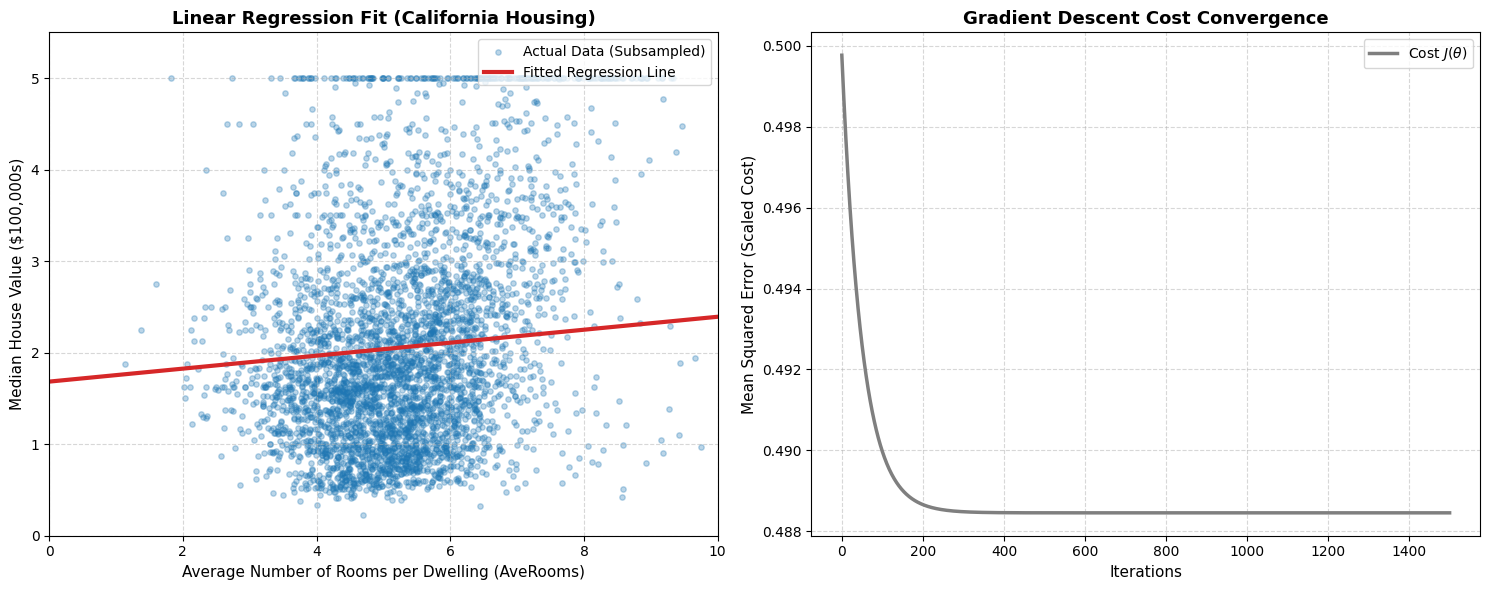

In [3]:
# Handle variable casing checks safely
current_y = Y if 'Y' in locals() else y
current_scaler_x = scaler_X if 'scaler_X' in locals() else scaler_x
current_scaler_y = scaler_Y if 'scaler_Y' in locals() else scaler_y

# Evaluate Performance
mse_gd = mean_squared_error(current_y, Y_pred_gd)
r2_gd = r2_score(current_y, Y_pred_gd)

print("----- MODEL EVALUATION RESULTS -----")
print(f"Gradient Descent:\n  - Mean Squared Error (MSE): {mse_gd:.4f}\n  - R-squared (R²):           {r2_gd:.4f}\n")

# Start Plotting
plt.figure(figsize=(15, 6))

# --- Plot 1: Fitted Line vs Actual Data Points ---
plt.subplot(1, 2, 1)

# .ravel() flattens vectors to 1D to keep matplotlib from throwing an error
plt.scatter(X[::5].ravel(), current_y[::5].ravel(), color='#1f77b4', alpha=0.3, s=15, label='Actual Data (Subsampled)')

# Generate line range bounds to cleanly visualize typical home dimensions (0 to 10 rooms)
x_line_raw = np.linspace(0, 10, 100).reshape(-1, 1)
x_line_scaled = current_scaler_x.transform(x_line_raw)
X_line_matrix = np.c_[np.ones((100, 1)), x_line_scaled]

# Predict along the line using your trained weights
y_line_pred_scaled = X_line_matrix.dot(theta_gd_scaled)
y_line_pred = current_scaler_y.inverse_transform(y_line_pred_scaled)

# Plot the regression line
plt.plot(x_line_raw.ravel(), y_line_pred.ravel(), color='#d62728', linewidth=3, label='Fitted Regression Line')

plt.xlim(0, 10)  # Zooms into standard room values to clip extreme outliers
plt.ylim(0, 5.5)
plt.xlabel('Average Number of Rooms per Dwelling (AveRooms)', fontsize=11)
plt.ylabel('Median House Value ($100,000s)', fontsize=11)
plt.title('Linear Regression Fit (California Housing)', fontsize=13, fontweight='bold')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

# --- Plot 2: Gradient Descent Cost Convergence Curve ---
plt.subplot(1, 2, 2)
plt.plot(range(iterations), cost_history, color='#7f7f7f', linewidth=2.5, label='Cost $J(\\theta)$')
plt.xlabel('Iterations', fontsize=11)
plt.ylabel('Mean Squared Error (Scaled Cost)', fontsize=11)
plt.title('Gradient Descent Cost Convergence', fontsize=13, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()